In [1]:
import requests
import pandas as pd
from concurrent.futures import ThreadPoolExecutor

START_DATE = "2023-01-01"
END_DATE = "2026-10-31"
REGION = "TenneT"  # Transmission control zone covering Bavaria

FILTERS = {
    "solar_mwh": "4068",         # Photovoltaik generation
    "grid_load_mwh": "410",      # Total grid load (Netzlast)
    "residual_load_mwh": "4359", # Residual load (Residuallast)
}

start_ms = int((pd.Timestamp(START_DATE, tz="UTC") - pd.Timedelta(days=7)).timestamp() * 1000)
end_ms = int((pd.Timestamp(END_DATE, tz="UTC") + pd.Timedelta(days=1)).timestamp() * 1000)

session = requests.Session()

def fetch_smard_series(col_name, filter_id):
    # 1. Get available weekly timestamps for this filter and region
    index_url = f"https://www.smard.de/app/chart_data/{filter_id}/{REGION}/index_hour.json"
    timestamps = session.get(index_url, timeout=30).json()["timestamps"]
    target_ts = [ts for ts in timestamps if start_ms <= ts <= end_ms]

    # 2. Fetch weekly JSON chunks in parallel
    def get_chunk(ts):
        url = f"https://www.smard.de/app/chart_data/{filter_id}/{REGION}/{filter_id}_{REGION}_hour_{ts}.json"
        r = session.get(url, timeout=30)
        if r.status_code == 200:
            return r.json().get("series", [])
        return []

    rows = []
    with ThreadPoolExecutor(max_workers=6) as executor:
        for chunk in executor.map(get_chunk, target_ts):
            rows.extend(chunk)

    df_s = pd.DataFrame(rows, columns=["timestamp_ms", col_name])
    df_s["timestamp_utc"] = pd.to_datetime(df_s["timestamp_ms"], unit="ms", utc=True)
    df_s[col_name] = pd.to_numeric(df_s[col_name], errors="coerce")
    df_s = df_s.drop(columns=["timestamp_ms"]).drop_duplicates(subset=["timestamp_utc"])
    print(f"Fetched '{col_name}' (filter {filter_id}): {len(df_s):,} hourly records")
    return df_s

# Fetch and merge all 3 grid series
smard_dfs = [fetch_smard_series(name, fid) for name, fid in FILTERS.items()]
grid_df = smard_dfs[0]
for next_df in smard_dfs[1:]:
    grid_df = grid_df.merge(next_df, on="timestamp_utc", how="outer")

# Clip cleanly to our target window
grid_df = grid_df[
    (grid_df["timestamp_utc"] >= pd.Timestamp(START_DATE, tz="UTC")) &
    (grid_df["timestamp_utc"] <= pd.Timestamp(END_DATE + " 23:00:00", tz="UTC"))
].sort_values("timestamp_utc").reset_index(drop=True)

print(f"\nSMARD TenneT Grid DataFrame ready: {grid_df.shape}")
grid_df.head()

Fetched 'solar_mwh' (filter 4068): 33,768 hourly records
Fetched 'grid_load_mwh' (filter 410): 33,768 hourly records
Fetched 'residual_load_mwh' (filter 4359): 33,768 hourly records

SMARD TenneT Grid DataFrame ready: (33600, 4)


,solar_mwh,timestamp_utc,grid_load_mwh,residual_load_mwh
0,1.00,2023-01-01 00:00:00+00:00,11649.50,-4085.75
1,1.25,2023-01-01 01:00:00+00:00,11749.25,-4167.25
2,1.00,2023-01-01 02:00:00+00:00,11295.25,-3860.00
3,1.50,2023-01-01 03:00:00+00:00,11264.00,-3754.75
4,1.50,2023-01-01 04:00:00+00:00,11290.75,-3687.75


In [2]:
import requests
import pandas as pd

BAVARIA_HUBS = {
    "Munich": (48.1351, 11.5820),
    "Nuremberg": (49.4521, 11.0767),
    "Wuerzburg": (49.7913, 9.9534),
}

HOURLY_VARS = [
    "temperature_2m",
    "cloud_cover",
    "shortwave_radiation",
    "direct_radiation",
    "diffuse_radiation",
    "wind_speed_10m",
    "precipitation",
]

weather_frames = []

for city, (lat, lon) in BAVARIA_HUBS.items():
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": START_DATE,
        "end_date": END_DATE,
        "hourly": ",".join(HOURLY_VARS),
        "timezone": "UTC",
    }
    resp = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=60)
    resp.raise_for_status()
    hourly_data = resp.json()["hourly"]

    df_city = pd.DataFrame(hourly_data)
    df_city["timestamp_utc"] = pd.to_datetime(df_city["time"], utc=True)
    df_city = df_city.drop(columns=["time"])
    weather_frames.append(df_city)
    print(f"Fetched Bavaria weather for {city}: {len(df_city):,} hours")

# Average hourly weather across the 3 Bavarian solar hubs
weather_bavaria = (
    pd.concat(weather_frames, ignore_index=True)
    .groupby("timestamp_utc", as_index=False)[HOURLY_VARS]
    .mean()
    .round(2)
)

# Merge Grid Telemetry + Bavaria Weather on exact UTC timestamp
master_df = (
    grid_df.merge(weather_bavaria, on="timestamp_utc", how="inner")
    .sort_values("timestamp_utc")
    .reset_index(drop=True)
)

output_file = "bavaria_solar_grid_2023_2026.csv"
master_df.to_csv(output_file, index=False)
print(f"\nSaved merged dataset to '{output_file}' — shape: {master_df.shape}")

Fetched Bavaria weather for Munich: 33,600 hours
Fetched Bavaria weather for Nuremberg: 33,600 hours
Fetched Bavaria weather for Wuerzburg: 33,600 hours

Saved merged dataset to 'bavaria_solar_grid_2023_2026.csv' — shape: (33600, 11)


In [3]:
import pandas as pd

df = pd.read_csv("bavaria_solar_grid_2023_2026.csv", parse_dates=["timestamp_utc"])

print("=== DATASET AUDIT ===")
print(f"Range: {df['timestamp_utc'].min()}  -->  {df['timestamp_utc'].max()}")
print(f"Rows:  {len(df):,}")

# Check for gaps in hourly timestamps
time_diffs = df["timestamp_utc"].diff().value_counts()
print("\nHourly step intervals (should be almost all 1 hour):")
print(time_diffs.head())

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nCorrelation with Solar PV Generation (solar_mwh):")
print(df.corr(numeric_only=True)["solar_mwh"].sort_values(ascending=False).round(3))

df.head()

=== DATASET AUDIT ===
Range: 2023-01-01 00:00:00+00:00  -->  2026-10-31 23:00:00+00:00
Rows:  33,600

Hourly step intervals (should be almost all 1 hour):
timestamp_utc
0 days 01:00:00    33599
Name: count, dtype: int64

Missing values per column:
solar_mwh              0
timestamp_utc          0
grid_load_mwh          0
residual_load_mwh      0
temperature_2m         0
cloud_cover            0
shortwave_radiation    0
direct_radiation       0
diffuse_radiation      0
wind_speed_10m         0
precipitation          0
dtype: int64

Correlation with Solar PV Generation (solar_mwh):
solar_mwh              1.000
shortwave_radiation    0.929
direct_radiation       0.896
diffuse_radiation      0.762
temperature_2m         0.501
grid_load_mwh          0.150
wind_speed_10m        -0.037
precipitation         -0.055
cloud_cover           -0.171
residual_load_mwh     -0.460
Name: solar_mwh, dtype: float64


,solar_mwh,timestamp_utc,grid_load_mwh,residual_load_mwh,temperature_2m,cloud_cover,shortwave_radiation,direct_radiation,diffuse_radiation,wind_speed_10m,precipitation
0,1.00,2023-01-01 00:00:00+00:00,11649.50,-4085.75,10.40,93.33,0.0,0.0,0.0,14.03,0.0
1,1.25,2023-01-01 01:00:00+00:00,11749.25,-4167.25,10.43,97.33,0.0,0.0,0.0,15.23,0.0
2,1.00,2023-01-01 02:00:00+00:00,11295.25,-3860.00,10.83,72.33,0.0,0.0,0.0,15.13,0.0
3,1.50,2023-01-01 03:00:00+00:00,11264.00,-3754.75,10.27,33.33,0.0,0.0,0.0,13.80,0.0
4,1.50,2023-01-01 04:00:00+00:00,11290.75,-3687.75,10.00,26.67,0.0,0.0,0.0,15.43,0.0


In [4]:
import numpy as np
import pandas as pd

df = pd.read_csv("bavaria_solar_grid_2023_2026.csv", parse_dates=["timestamp_utc"])
df = df.sort_values("timestamp_utc").drop_duplicates("timestamp_utc")

# 1. Enforce a strict 1-hour UTC timeline so lag shifts are never misaligned by gaps
full_range = pd.date_range(df["timestamp_utc"].min(), df["timestamp_utc"].max(), freq="h", tz="UTC")
df = df.set_index("timestamp_utc").reindex(full_range).rename_axis("timestamp_utc").reset_index()

# 2. Physics Feature A: Solar Elevation Angle for Bavaria's geographic center (48.9°N, 11.4°E)
LAT_DEG, LON_DEG = 48.9, 11.4
doy = df["timestamp_utc"].dt.dayofyear
utc_hour = df["timestamp_utc"].dt.hour + df["timestamp_utc"].dt.minute / 60.0

b_rad = 2 * np.pi * (doy - 81) / 365.0
declination_rad = np.radians(23.44 * np.sin(b_rad))
eot_min = 9.87 * np.sin(2 * b_rad) - 7.53 * np.cos(b_rad) - 1.5 * np.sin(b_rad)
solar_time = utc_hour + (LON_DEG / 15.0) + (eot_min / 60.0)
hour_angle_rad = np.radians(15.0 * (solar_time - 12.0))
lat_rad = np.radians(LAT_DEG)

sin_elev = (
    np.sin(lat_rad) * np.sin(declination_rad)
    + np.cos(lat_rad) * np.cos(declination_rad) * np.cos(hour_angle_rad)
)
df["solar_elevation_deg"] = np.degrees(np.arcsin(np.clip(sin_elev, -1.0, 1.0)))
df["is_daylight"] = (df["solar_elevation_deg"] > 0).astype(int)

# 3. Physics Feature B: PV Panel Thermal Derating & Radiation Geometry
# Estimated PV cell temp (NOCT ~ 45°C): T_cell = T_ambient + 0.03125 * Irradiance
df["pv_cell_temp_c"] = df["temperature_2m"] + 0.03125 * df["shortwave_radiation"]
df["temp_derating_factor"] = 1.0 - 0.004 * np.maximum(0.0, df["pv_cell_temp_c"] - 25.0)
df["effective_irradiance"] = df["shortwave_radiation"] * df["temp_derating_factor"]

# Fraction of radiation that is direct beam vs. diffuse sky light
df["direct_rad_ratio"] = np.clip(
    df["direct_radiation"] / (df["shortwave_radiation"] + 1e-5), 0.0, 1.0
)

# 4. Cyclical Time Encodings & Capacity-Growth Trend Proxy
df["hour_sin"] = np.sin(2 * np.pi * utc_hour / 24.0)
df["hour_cos"] = np.cos(2 * np.pi * utc_hour / 24.0)
df["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
df["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
df["days_since_start"] = (df["timestamp_utc"] - df["timestamp_utc"].min()).dt.total_seconds() / 86400.0
df["year"] = df["timestamp_utc"].dt.year

# 5. Weather Context (3-hour centered rolling averages capture passing cloud fronts)
df["rad_roll_3h"] = df["shortwave_radiation"].rolling(3, center=True, min_periods=1).mean()
df["cloud_roll_3h"] = df["cloud_cover"].rolling(3, center=True, min_periods=1).mean()

# 6. Leakage-Free Day-Ahead Target Lags (all strictly >= 24h in the past)
df["solar_lag_24h"] = df["solar_mwh"].shift(24)
df["solar_lag_48h"] = df["solar_mwh"].shift(48)
df["solar_lag_168h"] = df["solar_mwh"].shift(168)  # Same hour last week
df["solar_roll_mean_24h_lag24"] = df["solar_mwh"].shift(24).rolling(24, min_periods=12).mean()
df["solar_roll_max_168h_lag24"] = df["solar_mwh"].shift(24).rolling(168, min_periods=72).max()

# Save engineered dataset
df.to_csv("bavaria_solar_features_2023_2026.csv", index=False)
print(f"Feature engineering complete: {df.shape[0]:,} rows x {df.shape[1]} columns")
df[["timestamp_utc", "solar_mwh", "solar_elevation_deg", "effective_irradiance", "solar_lag_24h"]].tail()

Feature engineering complete: 33,600 rows x 30 columns


,timestamp_utc,solar_mwh,solar_elevation_deg,effective_irradiance,solar_lag_24h
33595,2026-10-31 19:00:00+00:00,0.0,-31.197792,0.0,0.0
33596,2026-10-31 20:00:00+00:00,0.0,-40.433291,0.0,0.0
33597,2026-10-31 21:00:00+00:00,0.0,-48.440445,0.0,0.0
33598,2026-10-31 22:00:00+00:00,0.0,-54.126447,0.0,0.0
33599,2026-10-31 23:00:00+00:00,0.0,-56.147143,0.0,0.0


In [5]:
import joblib
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("bavaria_solar_features_2023_2026.csv", parse_dates=["timestamp_utc"])

TARGET = "solar_mwh"
FEATURES = [
    # Weather & Irradiance
    "shortwave_radiation", "direct_radiation", "diffuse_radiation",
    "cloud_cover", "temperature_2m", "wind_speed_10m", "precipitation",
    "rad_roll_3h", "cloud_roll_3h",
    # Physics-Informed Features
    "solar_elevation_deg", "is_daylight", "pv_cell_temp_c",
    "temp_derating_factor", "effective_irradiance", "direct_rad_ratio",
    # Cyclical Time & Trend
    "hour_sin", "hour_cos", "doy_sin", "doy_cos", "days_since_start",
    # Day-Ahead Lags (strictly >= 24h prior)
    "solar_lag_24h", "solar_lag_48h", "solar_lag_168h",
    "solar_roll_mean_24h_lag24", "solar_roll_max_168h_lag24",
]

# Drop initial warm-up rows and any missing target/feature rows
model_df = df.dropna(subset=FEATURES + [TARGET]).copy()

# Strict Chronological Splits (No Random Shuffling!)
train_df = model_df[model_df["year"] <= 2024]
val_df   = model_df[model_df["year"] == 2025]
test_df  = model_df[model_df["year"] == 2026]

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_val,   y_val   = val_df[FEATURES],   val_df[TARGET]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET]

print(f"Train (2023-2024): {len(train_df):,} hrs | Val (2025): {len(val_df):,} hrs | Test (2026): {len(test_df):,} hrs\n")

# Physical post-processing: no negative PV generation, and 0 when sun is well below horizon
def apply_physics_clip(preds, elevation_deg):
    clipped = np.clip(preds, 0.0, None)
    clipped[elevation_deg <= -1.0] = 0.0
    return clipped

def evaluate(name, y_true, y_pred, daylight_mask):
    mae_all = mean_absolute_error(y_true, y_pred)
    rmse_all = np.sqrt(mean_squared_error(y_true, y_pred))
    r2_all = r2_score(y_true, y_pred)
    mae_day = mean_absolute_error(y_true[daylight_mask == 1], y_pred[daylight_mask == 1])
    return {
        "Model": name,
        "Test MAE (MWh)": round(mae_all, 1),
        "Daytime MAE (MWh)": round(mae_day, 1),
        "Test RMSE (MWh)": round(rmse_all, 1),
        "Test R2": round(r2_all, 4),
    }

day_mask_test = test_df["is_daylight"].values
elev_test = test_df["solar_elevation_deg"].values
results = []

# --- Model 1: Seasonal Naive Baseline (Yesterday Same Hour) ---
pred_naive = apply_physics_clip(test_df["solar_lag_24h"].values, elev_test)
results.append(evaluate("1. Seasonal Naive (24h Lag)", y_test, pred_naive, day_mask_test))

# --- Model 2: Ridge Regression (Linear Baseline inside sklearn Pipeline) ---
ridge_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10.0))
])
ridge_pipe.fit(X_train, y_train)
pred_ridge = apply_physics_clip(ridge_pipe.predict(X_test), elev_test)
results.append(evaluate("2. Ridge Regression (Linear)", y_test, pred_ridge, day_mask_test))

# --- Model 3: LightGBM Regressor (Early Stopping on 2025 Val Set) ---
lgbm_model = lgb.LGBMRegressor(
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=63,
    subsample_for_bin=50000,
    colsample_bytree=0.8,
    subsample=0.8,
    min_child_samples=30,
    random_state=42,
    n_jobs=-1,
)

lgbm_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)],
)

pred_lgbm = apply_physics_clip(lgbm_model.predict(X_test), elev_test)
results.append(evaluate("3. LightGBM (Physics + Lags)", y_test, pred_lgbm, day_mask_test))

# Display Benchmark Table
benchmark_df = pd.DataFrame(results)
print("=== 2026 HOLDOUT TEST BENCHMARK ===")
display(benchmark_df)

# Save predictions on 2026 holdout + trained model for SHAP & Streamlit
test_eval = test_df[["timestamp_utc", "solar_mwh", "solar_elevation_deg", "shortwave_radiation", "cloud_cover"]].copy()
test_eval["pred_naive"] = pred_naive
test_eval["pred_ridge"] = pred_ridge
test_eval["pred_lgbm"]  = pred_lgbm
test_eval.to_csv("bavaria_solar_test_predictions_2026.csv", index=False)

joblib.dump({"model": lgbm_model, "features": FEATURES}, "lgbm_bavaria_solar.joblib")
print(f"\nBest LightGBM iteration: {lgbm_model.best_iteration_}")
print("Saved 'lgbm_bavaria_solar.joblib' and 'bavaria_solar_test_predictions_2026.csv'")

Train (2023-2024): 17,376 hrs | Val (2025): 8,760 hrs | Test (2026): 7,296 hrs

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004963 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5399
[LightGBM] [Info] Number of data points in the train set: 17376, number of used features: 25
[LightGBM] [Info] Start training from score 2541.585060
=== 2026 HOLDOUT TEST BENCHMARK ===


,Model,Test MAE (MWh),Daytime MAE (MWh),Test RMSE (MWh),Test R2
0,1. Seasonal Naive (24h Lag),917.5,1709.4,1830.8,0.8990
1,2. Ridge Regression (Linear),730.6,1352.3,1319.5,0.9475
2,3. LightGBM (Physics + Lags),856.8,1594.3,1593.0,0.9235



Best LightGBM iteration: 186
Saved 'lgbm_bavaria_solar.joblib' and 'bavaria_solar_test_predictions_2026.csv'


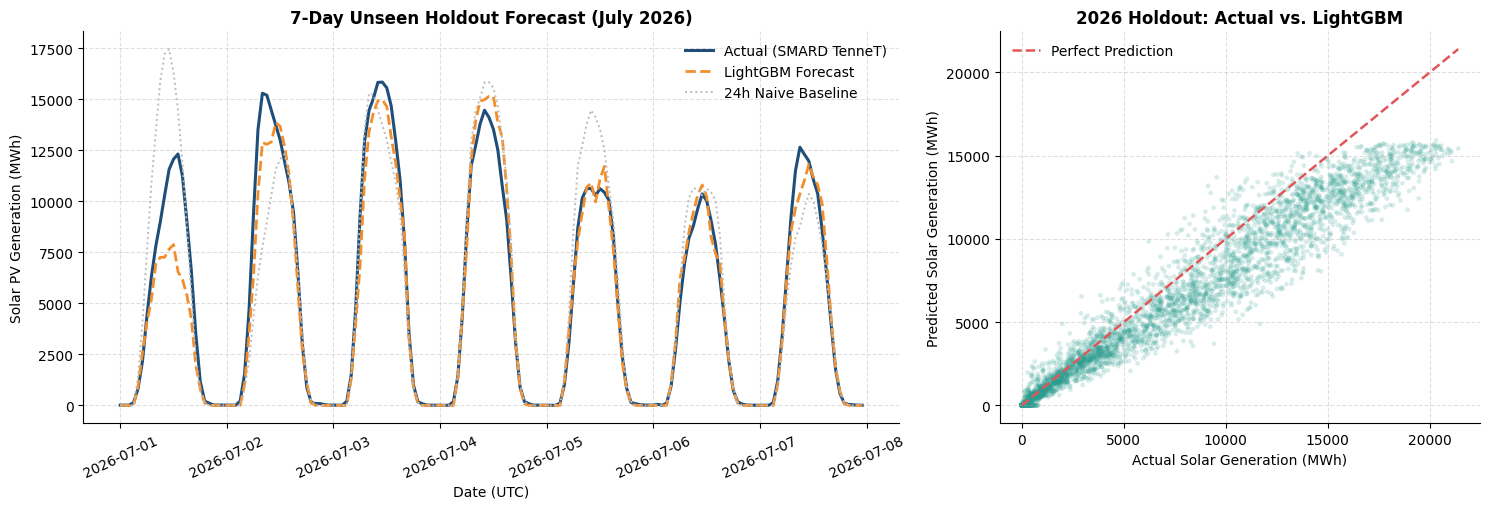

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

test_eval = pd.read_csv("bavaria_solar_test_predictions_2026.csv", parse_dates=["timestamp_utc"])

# Pick a 7-day slice in July 2026 to inspect clear vs. cloudy day tracking
week_df = test_eval[
    (test_eval["timestamp_utc"] >= "2026-07-01") &
    (test_eval["timestamp_utc"] < "2026-07-08")
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.7, 1]})

# Panel A: 7-Day Hourly Forecast vs. Actual
ax1.plot(week_df["timestamp_utc"], week_df["solar_mwh"], label="Actual (SMARD TenneT)", color="#1f4e79", linewidth=2.2)
ax1.plot(week_df["timestamp_utc"], week_df["pred_lgbm"], label="LightGBM Forecast", color="#f28e2b", linestyle="--", linewidth=2.0)
ax1.plot(week_df["timestamp_utc"], week_df["pred_naive"], label="24h Naive Baseline", color="#bbbbbb", linestyle=":", linewidth=1.4)
ax1.set_title("7-Day Unseen Holdout Forecast (July 2026)", fontweight="bold")
ax1.set_ylabel("Solar PV Generation (MWh)")
ax1.set_xlabel("Date (UTC)")
ax1.legend(frameon=False, loc="upper right")
ax1.grid(linestyle="--", alpha=0.4)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=25)

# Panel B: Predicted vs. Actual Scatter (All 2026 Holdout Hours)
ax2.scatter(test_eval["solar_mwh"], test_eval["pred_lgbm"], alpha=0.18, s=12, color="#2a9d8f", edgecolors="none")
max_val = max(test_eval["solar_mwh"].max(), test_eval["pred_lgbm"].max())
ax2.plot([0, max_val], [0, max_val], color="#e15759", linestyle="--", linewidth=1.8, label="Perfect Prediction")
ax2.set_title("2026 Holdout: Actual vs. LightGBM", fontweight="bold")
ax2.set_xlabel("Actual Solar Generation (MWh)")
ax2.set_ylabel("Predicted Solar Generation (MWh)")
ax2.legend(frameon=False, loc="upper left")
ax2.grid(linestyle="--", alpha=0.4)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("01_forecast_benchmark_2026.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
import numpy as np
import pandas as pd

df = pd.read_csv("bavaria_solar_features_2023_2026.csv", parse_dates=["timestamp_utc"])
df = df.sort_values("timestamp_utc").reset_index(drop=True)

# 1. Compute Plane-of-Array (POA) Irradiance for a 30° South-Facing Bavarian PV Array
LAT_DEG, LON_DEG, TILT_DEG = 48.9, 11.4, 30.0

doy = df["timestamp_utc"].dt.dayofyear
utc_hour = df["timestamp_utc"].dt.hour + df["timestamp_utc"].dt.minute / 60.0
b_rad = 2 * np.pi * (doy - 81) / 365.0
declination_rad = np.radians(23.44 * np.sin(b_rad))
eot_min = 9.87 * np.sin(2 * b_rad) - 7.53 * np.cos(b_rad) - 1.5 * np.sin(b_rad)
solar_time = utc_hour + (LON_DEG / 15.0) + (eot_min / 60.0)
hour_angle_rad = np.radians(15.0 * (solar_time - 12.0))

lat_rad = np.radians(LAT_DEG)
tilt_rad = np.radians(TILT_DEG)
eff_lat_rad = np.radians(LAT_DEG - TILT_DEG)  # Equivalent latitude for due-south tilt

sin_elev = (
    np.sin(lat_rad) * np.sin(declination_rad)
    + np.cos(lat_rad) * np.cos(declination_rad) * np.cos(hour_angle_rad)
)
cos_inc = (
    np.sin(eff_lat_rad) * np.sin(declination_rad)
    + np.cos(eff_lat_rad) * np.cos(declination_rad) * np.cos(hour_angle_rad)
)

# Geometric beam projection factor (bounded at low sun angles to prevent division spikes)
rb = np.where(sin_elev > 0.15, np.clip(cos_inc / np.maximum(sin_elev, 0.15), 0.0, 2.5), 0.0)

df["poa_irradiance"] = (
    df["direct_radiation"] * rb
    + df["diffuse_radiation"] * (1.0 + np.cos(tilt_rad)) / 2.0
)
df["poa_effective"] = df["poa_irradiance"] * df["temp_derating_factor"]
df["poa_roll_3h"] = df["poa_effective"].rolling(3, center=True, min_periods=1).mean()

# 2. Estimate Effective Fleet Capacity (MW) from Clean Sunny Hours (Strictly Causal)
# At Standard Test Conditions (1000 W/m²), Output (MW) ≈ Effective Capacity (MW) * (POA_eff / 1000)
clean_sun_mask = (
    (df["solar_elevation_deg"] >= 15.0)
    & (df["poa_effective"] >= 250.0)
    & (df["cloud_cover"] <= 50.0)
    & (df["solar_mwh"] > 0)
)

implied_cap_raw = pd.Series(np.nan, index=df.index)
implied_cap_raw[clean_sun_mask] = (
    df.loc[clean_sun_mask, "solar_mwh"]
    / (df.loc[clean_sun_mask, "poa_effective"] / 1000.0)
)

# Shift by 24h before rolling so day-ahead forecasts NEVER peek at target-day generation
df["estimated_capacity_mw"] = (
    implied_cap_raw
    .shift(24)
    .rolling(window=24 * 180, min_periods=24)
    .median()
    .ffill()
    .bfill()
)

# 3. Create Stationary Capacity-Factor Target & Normalized Lags
df["solar_cf"] = (df["solar_mwh"] / df["estimated_capacity_mw"]).clip(0.0, 1.5)

df["cf_lag_24h"] = df["solar_cf"].shift(24)
df["cf_lag_48h"] = df["solar_cf"].shift(48)
df["cf_lag_168h"] = df["solar_cf"].shift(168)
df["cf_roll_mean_24h_lag24"] = df["solar_cf"].shift(24).rolling(24, min_periods=12).mean()
df["cf_roll_max_168h_lag24"] = df["solar_cf"].shift(24).rolling(168, min_periods=72).max()

df.to_csv("bavaria_solar_cf_features_2023_2026.csv", index=False)

cap_by_year = df.groupby("year")["estimated_capacity_mw"].mean().round(0)
print("Estimated Effective PV Fleet Capacity by Year (MW):")
print(cap_by_year)

Estimated Effective PV Fleet Capacity by Year (MW):
year
2023    14319.0
2024    16647.0
2025    17979.0
2026    19249.0
Name: estimated_capacity_mw, dtype: float64


In [8]:
import joblib
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("bavaria_solar_cf_features_2023_2026.csv", parse_dates=["timestamp_utc"])
prev_eval = pd.read_csv("bavaria_solar_test_predictions_2026.csv", parse_dates=["timestamp_utc"])

CF_FEATURES = [
    # Weather & Tilted POA Irradiance
    "shortwave_radiation", "direct_radiation", "diffuse_radiation",
    "poa_irradiance", "poa_effective", "poa_roll_3h",
    "cloud_cover", "temperature_2m", "wind_speed_10m", "precipitation",
    "rad_roll_3h", "cloud_roll_3h",
    # Solar Geometry & Thermal Physics
    "solar_elevation_deg", "is_daylight", "pv_cell_temp_c",
    "temp_derating_factor", "direct_rad_ratio",
    # Cyclical Seasonality (No raw time trend!)
    "hour_sin", "hour_cos", "doy_sin", "doy_cos",
    # Normalized Day-Ahead Capacity-Factor Lags
    "cf_lag_24h", "cf_lag_48h", "cf_lag_168h",
    "cf_roll_mean_24h_lag24", "cf_roll_max_168h_lag24",
]

model_df = df.dropna(subset=CF_FEATURES + ["solar_cf", "solar_mwh", "estimated_capacity_mw"]).copy()

# Identical Chronological Splits
train_df = model_df[model_df["year"] <= 2024]
val_df   = model_df[model_df["year"] == 2025]
test_df  = model_df[model_df["year"] == 2026].copy()

X_train, y_train_cf = train_df[CF_FEATURES], train_df["solar_cf"]
X_val,   y_val_cf   = val_df[CF_FEATURES],   val_df["solar_cf"]
X_test              = test_df[CF_FEATURES]

# Train LightGBM on Stationary Capacity Factor Target
lgbm_cf = lgb.LGBMRegressor(
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=63,
    colsample_bytree=0.8,
    subsample=0.8,
    min_child_samples=30,
    random_state=42,
    n_jobs=-1,
)

lgbm_cf.fit(
    X_train, y_train_cf,
    eval_set=[(X_val, y_val_cf)],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)],
)

# Predict Capacity Factor -> Reconstruct MWh -> Apply Nighttime Physics Clip
pred_cf = np.clip(lgbm_cf.predict(X_test), 0.0, None)
pred_lgbm_cf_mwh = pred_cf * test_df["estimated_capacity_mw"].values
pred_lgbm_cf_mwh[test_df["solar_elevation_deg"].values <= -1.0] = 0.0

test_df["pred_lgbm_cf"] = pred_lgbm_cf_mwh

# Align on exact 2026 timestamps with Cell 5 predictions for an apples-to-apples comparison
compare_df = prev_eval.merge(
    test_df[["timestamp_utc", "estimated_capacity_mw", "poa_effective", "pred_lgbm_cf"]],
    on="timestamp_utc",
    how="inner",
)

# Evaluate Overall, Daytime, and Top-10% Peak Solar Hours (where tree clipping hurts most)
day_mask = compare_df["solar_elevation_deg"] > 0
peak_threshold = compare_df.loc[day_mask, "solar_mwh"].quantile(0.90)
peak_mask = compare_df["solar_mwh"] >= peak_threshold

def score_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Overall MAE (MWh)": round(mean_absolute_error(y_true, y_pred), 1),
        "Daytime MAE (MWh)": round(mean_absolute_error(y_true[day_mask], y_pred[day_mask]), 1),
        "Top-10% Peak MAE (MWh)": round(mean_absolute_error(y_true[peak_mask], y_pred[peak_mask]), 1),
        "Test RMSE (MWh)": round(np.sqrt(mean_squared_error(y_true, y_pred)), 1),
        "Test R2": round(r2_score(y_true, y_pred), 4),
    }

y_true = compare_df["solar_mwh"]
summary = pd.DataFrame([
    score_model("1. Seasonal Naive (24h Lag)", y_true, compare_df["pred_naive"]),
    score_model("2. Ridge Regression (Linear)", y_true, compare_df["pred_ridge"]),
    score_model("3. LightGBM (Raw MWh Target)", y_true, compare_df["pred_lgbm"]),
    score_model("4. LightGBM (Capacity-Normalized CF)", y_true, compare_df["pred_lgbm_cf"]),
])

print(f"=== 2026 HOLDOUT BENCHMARK (Top-10% Peak >= {peak_threshold:,.0f} MWh) ===")
display(summary)

# Save updated predictions & production model artifact
compare_df.to_csv("bavaria_solar_test_comparison_2026.csv", index=False)
joblib.dump(
    {
        "model": lgbm_cf,
        "features": CF_FEATURES,
        "latest_capacity_mw": float(df["estimated_capacity_mw"].iloc[-1]),
    },
    "lgbm_bavaria_solar_cf.joblib",
)
print(f"\nSaved 'lgbm_bavaria_solar_cf.joblib' (Best iteration: {lgbm_cf.best_iteration_})")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005748 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 5651
[LightGBM] [Info] Number of data points in the train set: 17376, number of used features: 26
[LightGBM] [Info] Start training from score 0.166968
=== 2026 HOLDOUT BENCHMARK (Top-10% Peak >= 16,131 MWh) ===


,Model,Overall MAE (MWh),Daytime MAE (MWh),Top-10% Peak MAE (MWh),Test RMSE (MWh),Test R2
0,1. Seasonal Naive (24h Lag),917.5,1709.4,1976.1,1830.8,0.8990
1,2. Ridge Regression (Linear),730.6,1352.3,2602.7,1319.5,0.9475
2,3. LightGBM (Raw MWh Target),856.8,1594.3,3909.2,1593.0,0.9235
3,4. LightGBM (Capacity-Normalized CF),558.6,1031.1,1613.9,1047.8,0.9669



Saved 'lgbm_bavaria_solar_cf.joblib' (Best iteration: 149)


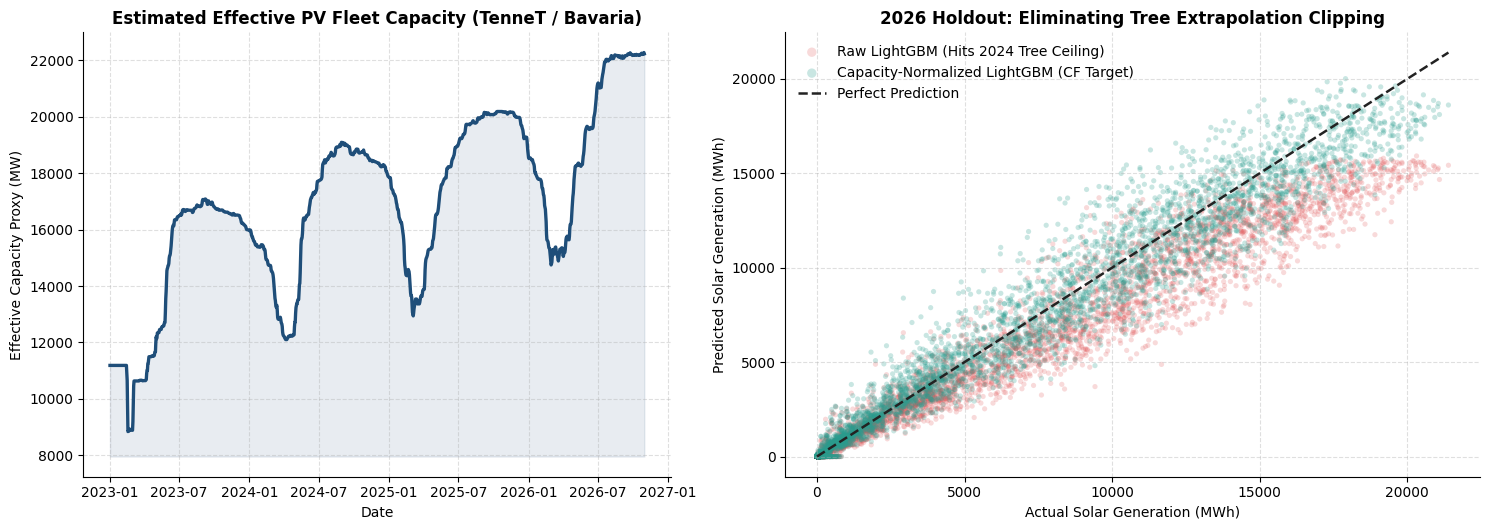

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

full_df = pd.read_csv("bavaria_solar_cf_features_2023_2026.csv", parse_dates=["timestamp_utc"])
comp_df = pd.read_csv("bavaria_solar_test_comparison_2026.csv", parse_dates=["timestamp_utc"])

# Daily average of estimated effective capacity for a clean growth curve
daily_cap = full_df.set_index("timestamp_utc")["estimated_capacity_mw"].resample("D").mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.1, 1.3]})

# Panel A: Bavaria Effective Solar Fleet Expansion (2023-2026)
ax1.plot(daily_cap.index, daily_cap.values, color="#1f4e79", linewidth=2.4)
ax1.fill_between(daily_cap.index, daily_cap.min() * 0.9, daily_cap.values, color="#1f4e79", alpha=0.1)
ax1.set_title("Estimated Effective PV Fleet Capacity (TenneT / Bavaria)", fontweight="bold")
ax1.set_ylabel("Effective Capacity Proxy (MW)")
ax1.set_xlabel("Date")
ax1.grid(linestyle="--", alpha=0.4)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# Panel B: Raw LightGBM (Clipped) vs. Capacity-Normalized LightGBM on 2026 Holdout
ax2.scatter(
    comp_df["solar_mwh"], comp_df["pred_lgbm"],
    alpha=0.22, s=14, color="#e15759", edgecolors="none", label="Raw LightGBM (Hits 2024 Tree Ceiling)"
)
ax2.scatter(
    comp_df["solar_mwh"], comp_df["pred_lgbm_cf"],
    alpha=0.25, s=14, color="#2a9d8f", edgecolors="none", label="Capacity-Normalized LightGBM (CF Target)"
)

max_val = max(comp_df["solar_mwh"].max(), comp_df["pred_lgbm_cf"].max())
ax2.plot([0, max_val], [0, max_val], color="#222222", linestyle="--", linewidth=1.8, label="Perfect Prediction")

ax2.set_title("2026 Holdout: Eliminating Tree Extrapolation Clipping", fontweight="bold")
ax2.set_xlabel("Actual Solar Generation (MWh)")
ax2.set_ylabel("Predicted Solar Generation (MWh)")
ax2.legend(frameon=False, loc="upper left", markerscale=1.8)
ax2.grid(linestyle="--", alpha=0.4)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("02_capacity_normalization_impact.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
!pip install -q shap

import joblib
import numpy as np
import pandas as pd
import shap

# 1. Load trained capacity-normalized LightGBM artifact and feature dataset
artifact = joblib.load("lgbm_bavaria_solar_cf.joblib")
lgbm_cf = artifact["model"]
CF_FEATURES = artifact["features"]

df = pd.read_csv("bavaria_solar_cf_features_2023_2026.csv", parse_dates=["timestamp_utc"])

# 2. Filter to unseen 2026 daytime hours only
test_day = (
    df[(df["year"] == 2026) & (df["solar_elevation_deg"] > 0)]
    .dropna(subset=CF_FEATURES + ["solar_mwh", "solar_cf", "estimated_capacity_mw"])
    .reset_index(drop=True)
)

X_day = test_day[CF_FEATURES]

# Readable display names for publication-ready charts
FEATURE_LABELS = {
    "poa_effective": "Tilted POA Irradiance (Temp-Adjusted)",
    "poa_irradiance": "Tilted POA Irradiance (Raw)",
    "poa_roll_3h": "3h Rolling POA Irradiance",
    "shortwave_radiation": "Horizontal Shortwave Radiation",
    "direct_radiation": "Direct Beam Radiation",
    "diffuse_radiation": "Diffuse Sky Radiation",
    "rad_roll_3h": "3h Rolling Shortwave Radiation",
    "cloud_cover": "Cloud Cover (%)",
    "cloud_roll_3h": "3h Rolling Cloud Cover (%)",
    "temperature_2m": "Ambient Temperature (°C)",
    "pv_cell_temp_c": "Estimated PV Cell Temp (°C)",
    "temp_derating_factor": "Thermal Derating Factor",
    "solar_elevation_deg": "Solar Elevation Angle (°)",
    "direct_rad_ratio": "Direct-to-Total Radiation Ratio",
    "wind_speed_10m": "Wind Speed (10m)",
    "precipitation": "Precipitation (mm)",
    "is_daylight": "Daylight Indicator",
    "hour_sin": "Hour of Day (sin)",
    "hour_cos": "Hour of Day (cos)",
    "doy_sin": "Day of Year (sin)",
    "doy_cos": "Day of Year (cos)",
    "cf_lag_24h": "Capacity Factor Lag (24h)",
    "cf_lag_48h": "Capacity Factor Lag (48h)",
    "cf_lag_168h": "Capacity Factor Lag (168h / 1wk)",
    "cf_roll_mean_24h_lag24": "Prior 24h Mean Capacity Factor",
    "cf_roll_max_168h_lag24": "Prior 7-Day Peak Capacity Factor",
}
display_names = [FEATURE_LABELS.get(f, f) for f in CF_FEATURES]

# 3. Compute exact TreeSHAP values for all 2026 daytime hours
explainer = shap.TreeExplainer(lgbm_cf)
shap_exp = explainer(X_day)

# Rebuild Explanation with readable labels (and scalar/array-safe base values)
base_vals = (
    np.full(len(X_day), float(shap_exp.base_values))
    if np.ndim(shap_exp.base_values) == 0
    else np.asarray(shap_exp.base_values, dtype=float).ravel()
)

shap_exp_global = shap.Explanation(
    values=shap_exp.values,
    base_values=base_vals,
    data=X_day.values,
    feature_names=display_names,
)

# Print Top 10 Global Feature Impacts (for your README metrics)
mean_abs_shap = pd.Series(np.abs(shap_exp.values).mean(axis=0), index=display_names)
top10 = mean_abs_shap.sort_values(ascending=False).head(10)

print(f"Computed exact TreeSHAP values for {len(X_day):,} daytime hours in 2026.")
print("\n=== TOP 10 GLOBAL DRIVERS (Mean |SHAP| in Capacity Factor Points) ===")
for feat, val in top10.items():
    print(f"  {feat:<40s} : {val:.4f} CF  ({val*100:.2f} pct pts)")

Computed exact TreeSHAP values for 3,861 daytime hours in 2026.

=== TOP 10 GLOBAL DRIVERS (Mean |SHAP| in Capacity Factor Points) ===
  Capacity Factor Lag (24h)                : 0.1576 CF  (15.76 pct pts)
  Solar Elevation Angle (°)                : 0.0717 CF  (7.17 pct pts)
  3h Rolling POA Irradiance                : 0.0406 CF  (4.06 pct pts)
  Day of Year (sin)                        : 0.0257 CF  (2.57 pct pts)
  Hour of Day (sin)                        : 0.0257 CF  (2.57 pct pts)
  Capacity Factor Lag (48h)                : 0.0205 CF  (2.05 pct pts)
  3h Rolling Shortwave Radiation           : 0.0189 CF  (1.89 pct pts)
  Capacity Factor Lag (168h / 1wk)         : 0.0112 CF  (1.12 pct pts)
  Direct-to-Total Radiation Ratio          : 0.0082 CF  (0.82 pct pts)
  Ambient Temperature (°C)                 : 0.0063 CF  (0.63 pct pts)


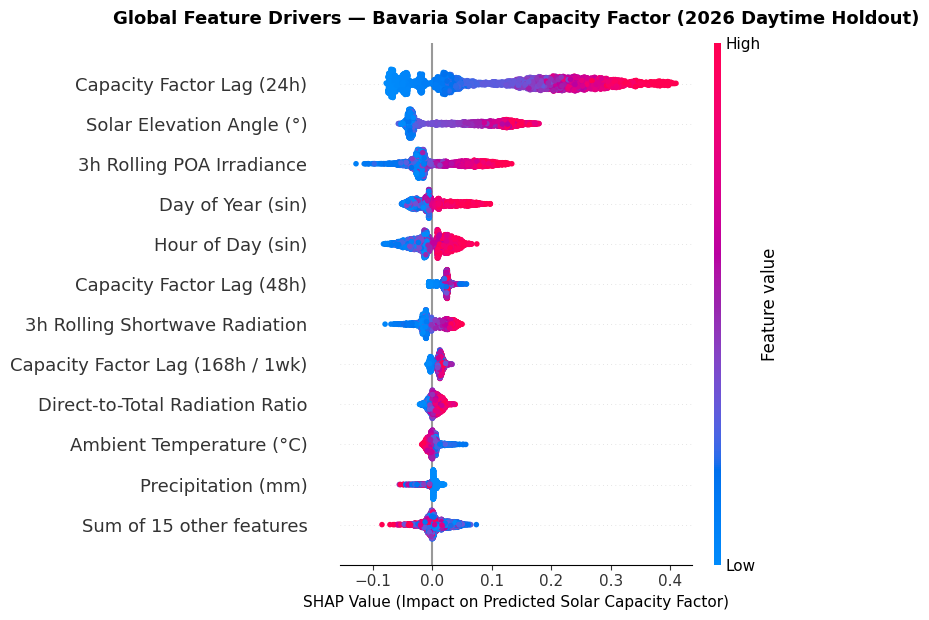

Saved '03_shap_global_beeswarm.png'


In [11]:
import matplotlib.pyplot as plt
import shap

plt.figure(figsize=(10.5, 6.5))
shap.plots.beeswarm(shap_exp_global, max_display=12, show=False)

ax = plt.gca()
ax.set_title(
    "Global Feature Drivers — Bavaria Solar Capacity Factor (2026 Daytime Holdout)",
    fontsize=13,
    fontweight="bold",
    pad=14,
)
ax.set_xlabel("SHAP Value (Impact on Predicted Solar Capacity Factor)", fontsize=11)

plt.tight_layout()
plt.savefig("03_shap_global_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print("Saved '03_shap_global_beeswarm.png'")

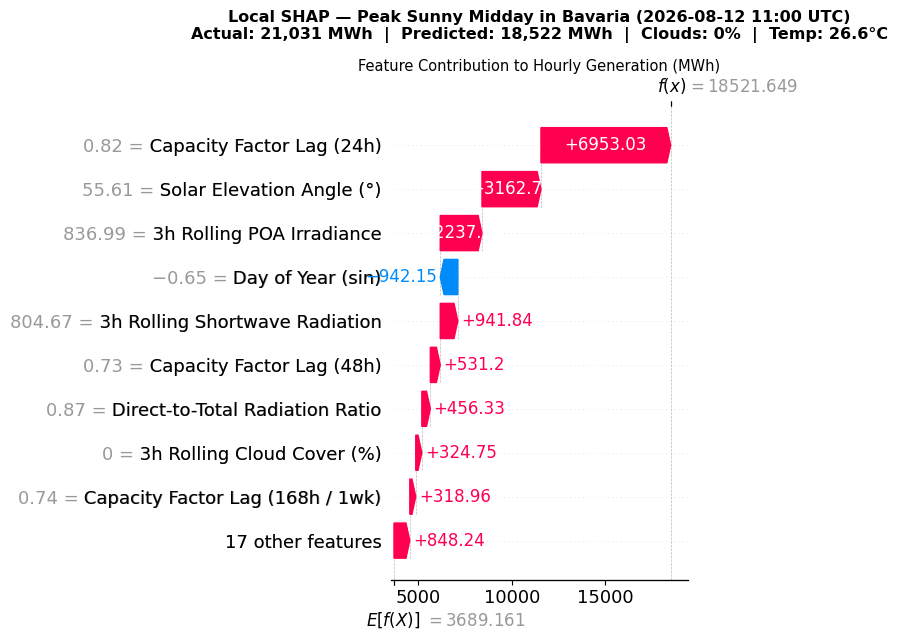

[Local SHAP — Peak Sunny Midday in Bavaria] 2026-08-12 11:00 UTC -> Actual: 21,031 MWh | Predicted: 18,522 MWh | Error: -2,509 MWh | Saved '04_shap_waterfall_sunny.png'


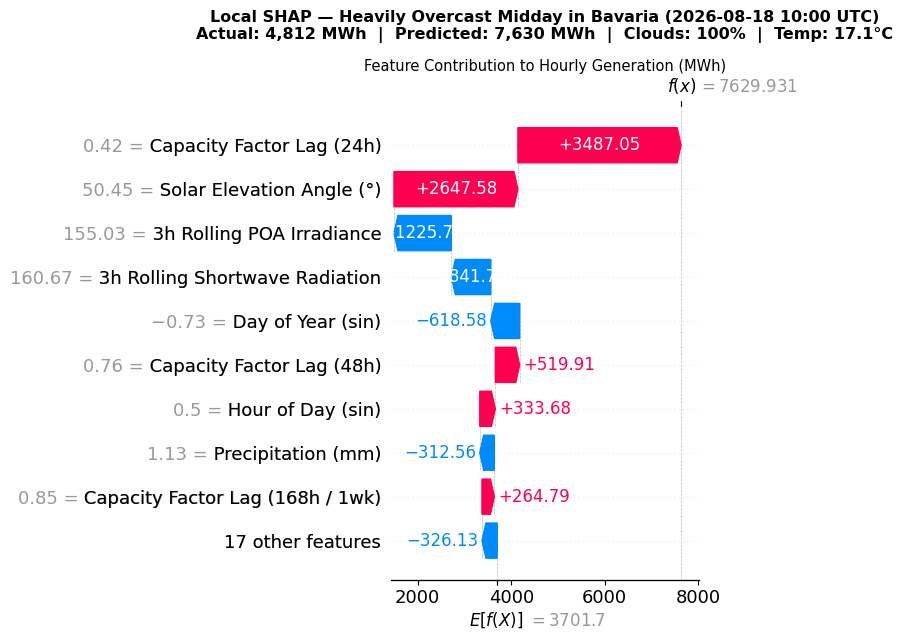

[Local SHAP — Heavily Overcast Midday in Bavaria] 2026-08-18 10:00 UTC -> Actual: 4,812 MWh | Predicted: 7,630 MWh | Error: +2,818 MWh | Saved '05_shap_waterfall_cloudy.png'


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Restrict to summer midday hours (May–Aug, 10:00–13:00 UTC = 12:00–15:00 CEST)
summer_midday = test_day[
    test_day["timestamp_utc"].dt.month.isin([5, 6, 7, 8])
    & test_day["timestamp_utc"].dt.hour.isin([10, 11, 12, 13])
]

# Case A: Peak Sunny Midday Hour (lowest cloud cover, highest actual generation)
sunny_candidates = summer_midday[summer_midday["cloud_cover"] <= 15]
sunny_idx = (
    sunny_candidates["solar_mwh"].idxmax()
    if not sunny_candidates.empty
    else summer_midday["solar_mwh"].idxmax()
)

# Case B: Overcast / Rainy Midday Hour (heavy cloud cover, lowest actual generation)
cloudy_candidates = summer_midday[summer_midday["cloud_cover"] >= 90]
cloudy_idx = (
    cloudy_candidates["solar_mwh"].idxmin()
    if not cloudy_candidates.empty
    else summer_midday["solar_mwh"].idxmin()
)

def plot_local_mwh_waterfall(row_idx, case_title, filename):
    row = test_day.loc[row_idx]
    cap_mw = float(row["estimated_capacity_mw"])

    # Scale CF SHAP values & baseline by this hour's effective fleet capacity -> exact MWh
    local_exp_mwh = shap.Explanation(
        values=shap_exp_global.values[row_idx] * cap_mw,
        base_values=float(shap_exp_global.base_values[row_idx]) * cap_mw,
        data=np.round(X_day.iloc[row_idx].values, 2),
        feature_names=display_names,
    )

    pred_mwh = float(local_exp_mwh.base_values + local_exp_mwh.values.sum())
    actual_mwh = float(row["solar_mwh"])
    ts_str = row["timestamp_utc"].strftime("%Y-%m-%d %H:%M UTC")

    plt.figure(figsize=(10.5, 5.8))
    shap.plots.waterfall(local_exp_mwh, max_display=10, show=False)
    plt.title(
        f"{case_title} ({ts_str})\n"
        f"Actual: {actual_mwh:,.0f} MWh  |  Predicted: {pred_mwh:,.0f} MWh  |  "
        f"Clouds: {row['cloud_cover']:.0f}%  |  Temp: {row['temperature_2m']:.1f}°C",
        fontsize=11.5,
        fontweight="bold",
        pad=14,
    )
    plt.xlabel("Feature Contribution to Hourly Generation (MWh)", fontsize=10.5)
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print(
        f"[{case_title}] {ts_str} -> Actual: {actual_mwh:,.0f} MWh | "
        f"Predicted: {pred_mwh:,.0f} MWh | Error: {pred_mwh - actual_mwh:+,.0f} MWh | "
        f"Saved '{filename}'"
    )

plot_local_mwh_waterfall(
    sunny_idx,
    "Local SHAP — Peak Sunny Midday in Bavaria",
    "04_shap_waterfall_sunny.png",
)

plot_local_mwh_waterfall(
    cloudy_idx,
    "Local SHAP — Heavily Overcast Midday in Bavaria",
    "05_shap_waterfall_cloudy.png",
)